# Quality Control with SpotSweeper (Visium HD Binned)

## Introduction

In the [previous notebook](./04-quality_control_VisiumHD_segmented.ipynb), we applied spatially-aware quality control to _cell-segmented_ Visium HD polygons (`SpatialFeatureExperiment`). As noted in that introduction, the exact same QC principles and `SpotSweeper` workflows apply directly to binned Visium HD grids. 

In this follow-up notebook, we adapt our QC pipeline to the **16-µm binned `SpatialExperiment` (`spe`)** dataset that we cropped to our Region of Interest (ROI) and pre-filtered (> 50 UMIs) in [Notebook 01](./01-data_ingestion_SpatialExperiment_object.ipynb). Because we already covered the theoretical foundations of global MAD thresholds and local spatial k-NN Z-scores in Notebook 04, we focus here on how **grid binning vs. cell segmentation** changes data structures, visualization functions, metric distributions, and outlier behavior.

Indeed, cell segmentation only draws polygons around stained nuclei/cell boundaries, leaving internal glandular lumens and stromal clefts empty. In contrast, 16-µm bins tile the entire ROI continuously. Aside from the 453 nearly empty luminal bins (≤ 50 UMIs) already removed in Notebook 01, our spatial grid forms an uninterrupted square lattice across the tissue.

> **Choosing the right bin size (2 µm vs. 8 µm vs. 16 µm):** While Visium HD physically captures RNA on a 2×2 µm grid, raw 2-µm squares are sub-cellular (~30.5 mean UMIs/square; >8.7 million squares slide-wide). At 2 µm, extreme zero-inflation creates discrete "shot noise" in mitochondrial percentages, and a 36-neighbor $k$-NN window only spans 12 × 12 µm, comparing a single cell to itself rather than its surrounding tissue neighborhood. Moving to 8-µm bins (~488 mean UMIs/bin) approximates single-cell scale, but quadruples the computational footprint (~546k bins slide-wide, ~90k in our ROI). Aggregating into **16-µm bins** (~1,946 mean UMIs and ~1,275 genes per bin across 21,966 ROI bins) yields smooth, continuous transcriptomic distributions ideal for rapid `SpotSweeper` Z-score modeling, at the biological cost of pooling multiple overlapping cells per square.

## Learning objectives

- Restore an HDF5-backed `SpatialExperiment` (`spe`) object using `HDF5Array`.
- Adapt spatial QC visualizations from `Voyager` polygon geometries to `ggspavis::plotCoords()` point grids using `scale_color_gradientn()`.
- Compare QC metric distributions between 16-µm multi-cell bins and segmented single cells.
- Evaluate why naive global cutoffs penalize intact glandular structures in binned data, and calibrate relaxed global floors alongside `SpotSweeper` local Z-scores.

## Environment setup & data import

### Loading libraries

In [1]:
suppressPackageStartupMessages(suppressWarnings({
  # Core Spatial & Single-Cell Infrastructure
  library(HDF5Array)
  library(SpatialExperiment)

  # Quality Control Frameworks
  library(scuttle)
  library(SpotSweeper)

  # Visualization & Distribution Plotting
  library(scater)    # for ggcells()
  library(ggplot2)
  library(patchwork)
  library(ggside)    # for marginal histograms
  library(ggspavis)  # for plotObsQC() and plotCoords()
}))

### Restoring the binned SPE dataset

We reload the 16-µm binned Visium HD dataset that we cropped to our Region of Interest (ROI), pre-filtered to exclude empty/ambient-only bins (≤ 50 UMIs), and saved at the end of [Notebook 01](./01-data_ingestion_SpatialExperiment_object.ipynb). 

Unlike the segmented `SpatialFeatureExperiment` object (which was serialized via `alabaster.sfe::readObject()`), our binned `SpatialExperiment` object uses an out-of-memory `DelayedMatrix` (HDF5 backend). We use `loadHDF5SummarizedExperiment()` from `HDF5Array` to reconstruct the `spe` object (**18,085 genes × 21,966 bins**) directly from the `output/` directory.

In [2]:
# Load the pre-cropped and filtered SpatialExperiment object
out_dir <- "output"

spe <- loadHDF5SummarizedExperiment(
  dir = out_dir,
  prefix = "spe_visiumHD_CRC_P2_filtered_"
)

# Verify the restored object dimensions, metadata and spatial coordinates
spe

class: SpatialExperiment 
dim: 18085 21966 
metadata(2): resouces spatialList
assays(1): counts
rownames(18085): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(3): ID Symbol Type
colnames(21966): s_016um_00144_00175-1 s_016um_00204_00145-1 ...
  s_016um_00231_00291-1 s_016um_00193_00227-1
colData names(12): barcode in_tissue ... in_cell sample_id
reducedDimNames(0):
mainExpName: Gene Expression
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

### Macro histological overview (H&E reference map)

Before computing molecular metrics, we inspect the underlying low-resolution H&E histology image stored in `imgData(spe)`. Note that in this `SpatialExperiment` object, `spatialCoords(spe)` (`pxl_col_in_fullres`, `pxl_row_in_fullres`) are stored in **full-resolution pixels** rather than microns.

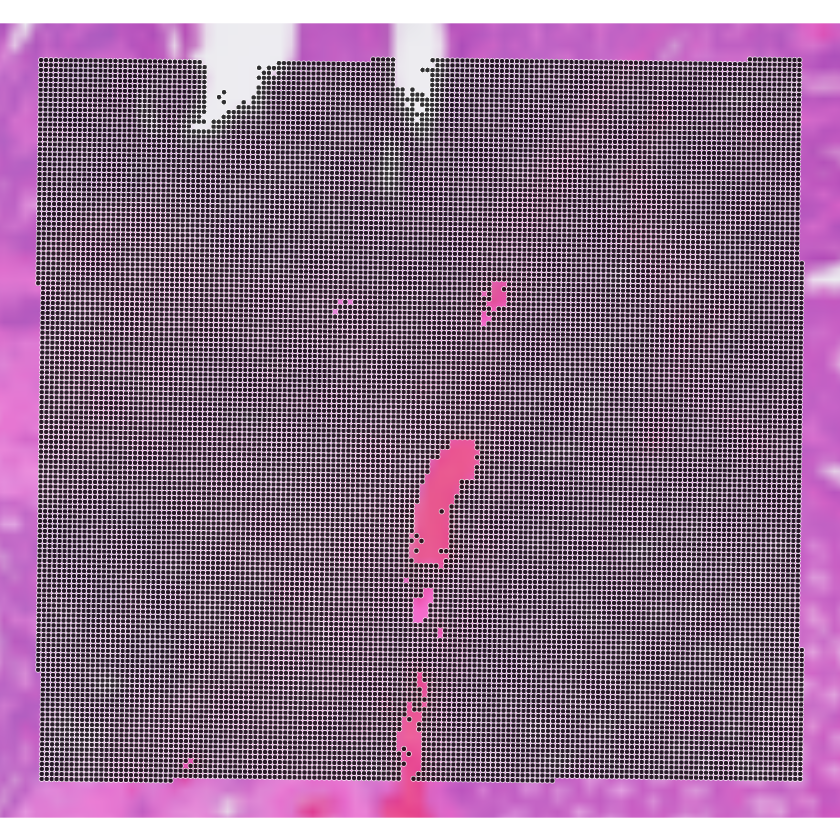

In [3]:
# Plot the full-slide H&E image
plotVisium(spe, zoom = TRUE)

## Computing per-bin QC metrics

### Calculating library size, gene diversity, and mitochondrial fraction

Just as with segmented cells, we identify mitochondrial transcripts (`^MT-`) and run `scuttle::addPerCellQCMetrics()`. Because `scuttle` operates natively on `SpatialExperiment` objects and `DelayedMatrix` assays, the workflow code is identical—each column now represents a fixed 16 × 16 µm square bin (256 µm²) rather than a variable-area cell polygon.

In [4]:
# Identify mitochondrial genes using the standard "MT-" prefix
is_mito <- rownames(spe)[grepl("^MT-", rownames(spe))]

# Inspect the identified mitochondrial gene symbols
is_mito

[1] "MT-ND1"  "MT-ND2"  "MT-CO2"  "MT-ATP6" "MT-CO3"  "MT-ND3"  "MT-ND4L"
 [8] "MT-ND4"  "MT-ND5"  "MT-ND6"  "MT-CYB"

In [5]:
# Compute per-cell QC metrics and append them directly to colData
spe <- addPerCellQCMetrics(spe, subsets = list(Mito = is_mito))

Warning message in addPerCellQCMetrics(spe, subsets = list(Mito = is_mito)):
"'addPerCellQCMetrics' est obsolète.
Utilisez plutôt ‘scrapper::quickRnaQc.se’.
Voir help("Deprecated")"
Warning message in .per_cell_qc_metrics(assay(x, assay.type), subsets = subsets, :
"'perCellQCMetrics' est obsolète.
Utilisez plutôt ‘scrapper::computeRnaQcMetrics’.
Voir help("Deprecated")"


using unknown matrix fallback for 'HDF5ArraySeed'



In [6]:
# Inspect the newly calculated QC columns in colData
# Notice the square brackets [ , columns] AFTER colData(spe)
colData(spe)[, c("sum", "detected", "subsets_Mito_percent")] |> head()

DataFrame with 6 rows and 3 columns
                            sum  detected subsets_Mito_percent
                      <numeric> <numeric>            <numeric>
s_016um_00144_00175-1       531       433              1.31827
s_016um_00204_00145-1      1324      1027              2.34139
s_016um_00237_00273-1      5458      2901              9.96702
s_016um_00191_00159-1      1275       771              1.49020
s_016um_00245_00233-1      2759      1922              4.82059
s_016um_00116_00279-1      1978      1308              6.47118

## Evaluating global outliers & fixed thresholds

As established in the [previous notebook](./04-quality_control_VisiumHD_segmented.ipynb), standard single-cell workflows filter low-quality observations using fixed global cutoffs applied uniformly across the dataset. When adapting this approach to 16-µm binned Visium HD data, we can directly test the community benchmark from the [OSTA book](https://lmweber.org/OSTA/pages/seq-workflow-visium-hd-bin.html#dependencies), which removes 8-µm bins with fewer than 100 UMIs, scaling to **400 UMIs for 16-µm bins** due to the 4-fold increase in surface area (256 µm² vs. 64 µm²).

Before applying any hard filtering, we examine the joint bivariate distributions of our QC metrics (`ggcells` scatter plots with 2D density contours and `ggside` marginal histograms), testing these initial candidate cutoffs:

- **Library size (`sum`):** 400 UMIs
- **Transcript diversity (`detected`):** 200 unique genes
- **Mitochondrial proportion (`subsets_Mito_percent`):** 10%

In [7]:
# Initial candidate cutoffs (from Section 3, for visual comparison)
init_min_sum      <- 400
init_min_detected <- 200
init_max_mito     <- 10

In [8]:
# Plot 1: Library size vs. detected genes with marginal histograms
p1 <- ggcells(spe, aes(x = detected, y = sum)) + 
  geom_point(alpha = 0.75, size = 1) +
  geom_density_2d(color = "blue") +
  scale_x_log10() +
  scale_y_log10() +
  geom_xsidehistogram(bins = 50, fill = "gray70", color = "white") + 
  geom_ysidehistogram(bins = 50, fill = "gray70", color = "white") + 
  geom_vline(xintercept = init_min_detected, color = "red", linetype = "dashed") +
  geom_hline(yintercept = init_min_sum, color = "red", linetype = "dashed") +
  labs(
    x = "Detected Genes (log10)", 
    y = "Total UMIs (log10)",
    title = "Library Size vs. Detected Genes"
  ) +
  theme_classic() +
  ggside::theme_ggside_void()

# Plot 2: Mitochondrial proportion vs. detected genes with marginal histograms
p2 <- ggcells(spe, aes(x = detected, y = subsets_Mito_percent)) + 
  geom_point(alpha = 0.75, size = 1) +
  geom_density_2d(color = "blue") +
  scale_x_log10() +
  geom_xsidehistogram(bins = 50, fill = "gray70", color = "white") + 
  geom_ysidehistogram(bins = 50, fill = "gray70", color = "white") + 
  geom_vline(xintercept = init_min_detected, color = "red", linetype = "dashed") +
  geom_hline(yintercept = init_max_mito, color = "red", linetype = "dashed") +
  labs(
    x = "Detected Genes (log10)", 
    y = "Mitochondrial Fraction (%)",
    title = "Mitochondrial Fraction vs. Detected Genes"
  ) +
  theme_classic() +
  ggside::theme_ggside_void()

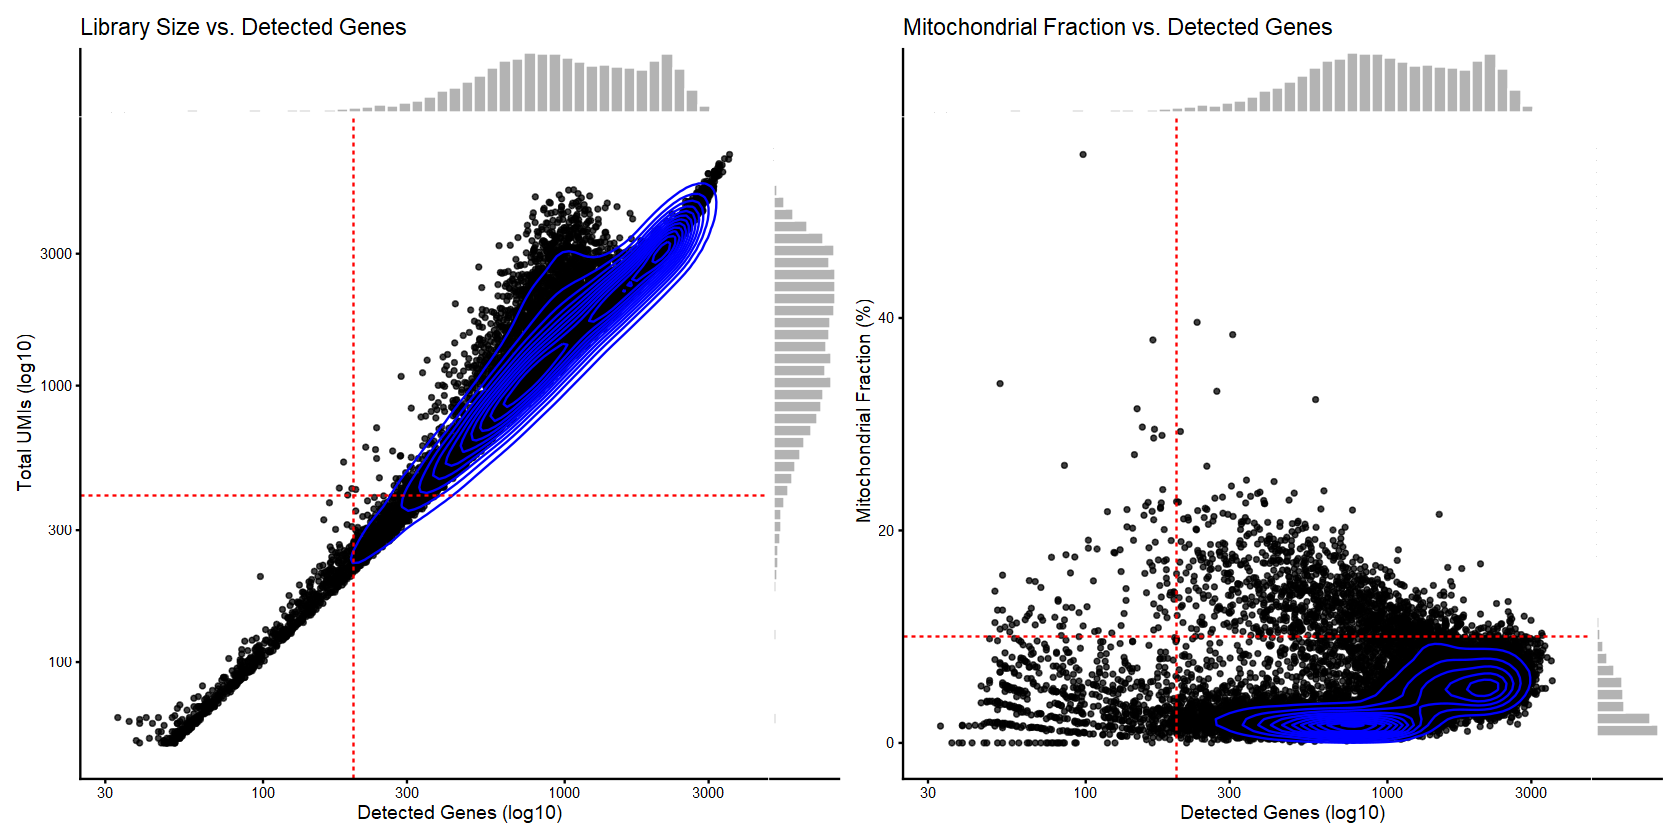

In [9]:
options(repr.plot.width = 14, repr.plot.height = 7)

# Combine panels side-by-side using patchwork
p1 + p2

Looking at the bivariate plots above, the 2D trajectory between library size (`sum`) and detected genes (`detected`) is very similar to the segmented dataset, and our initial candidate cutoffs fit the main body of the marginal histograms reasonably well. However, the mitochondrial fraction (`subsets_Mito_percent`) distribution is noticeably shifted because each 16-µm square pools transcripts from multiple overlapping cells.

### Quantifying candidate global exclusions

To measure the practical impact of these initial candidate cutoffs across our 21,966 bins, we store each threshold as a logical flag in `colData(spe)` (`TRUE` = flagged for exclusion) and tabulate the resulting bin losses individually and in combination.

In [10]:
# Flag cells failing each candidate global threshold (TRUE = flagged as low quality)
spe[["qc_lib_size"]]  <- spe[["sum"]] < init_min_sum
spe[["qc_detected"]]  <- spe[["detected"]] < init_min_detected
spe[["qc_mito_prop"]] <- spe[["subsets_Mito_percent"]] > init_max_mito

# Tabulate the number of cells flagged by each criterion
qc_cols <- grep("^qc", names(colData(spe)))
sapply(colData(spe)[qc_cols], table)

,qc_lib_size,qc_detected,qc_mito_prop
FALSE,20538,21272,20608
TRUE,1428,694,1358


Applying these initial global cutoffs to our 21,966 bins flags **1,428 bins (6.5%)** for low library size (`qc_lib_size`), **694 bins (3.2%)** for low gene diversity (`qc_detected`), and **1,358 bins (6.2%)** for high mitochondrial fraction (`qc_mito_prop`). 

Compared to the segmented cell dataset in Notebook 04 (where naive global cutoffs eliminated nearly 14% of cells overwhelmingly due to small or low-UMI cell polygons) the 16-µm binned grid loses fewer observations to the library size floor because each 256 µm² square pools transcripts from multiple overlapping cells (and empty bins with ≤ 50 UMIs were already pre-filtered in Notebook 01). However, notice that the 10% mitochondrial cutoff now accounts for nearly as many exclusions (1,358 bins) as library size (1,428 bins). To see whether these flagged bins represent true technical damage or healthy, metabolically active tissue structures, we map them onto our spatial coordinates.

### Spatial mapping of QC metrics

To see how these molecular metrics distribute across the tissue architecture, we map them onto physical coordinates. Because our `SpatialExperiment` (`spe`) object stores bin centroids in `spatialCoords(spe)` rather than `sf` polygon geometries (`cellSeg`), we use `ggspavis::plotCoords()` instead of `Voyager::plotSpatialFeature()`, which requires mapping our continuous color scales to the point `color` aesthetic (`scale_color_gradientn()`) rather than polygon `fill` (`scale_fill_gradientn()`).

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


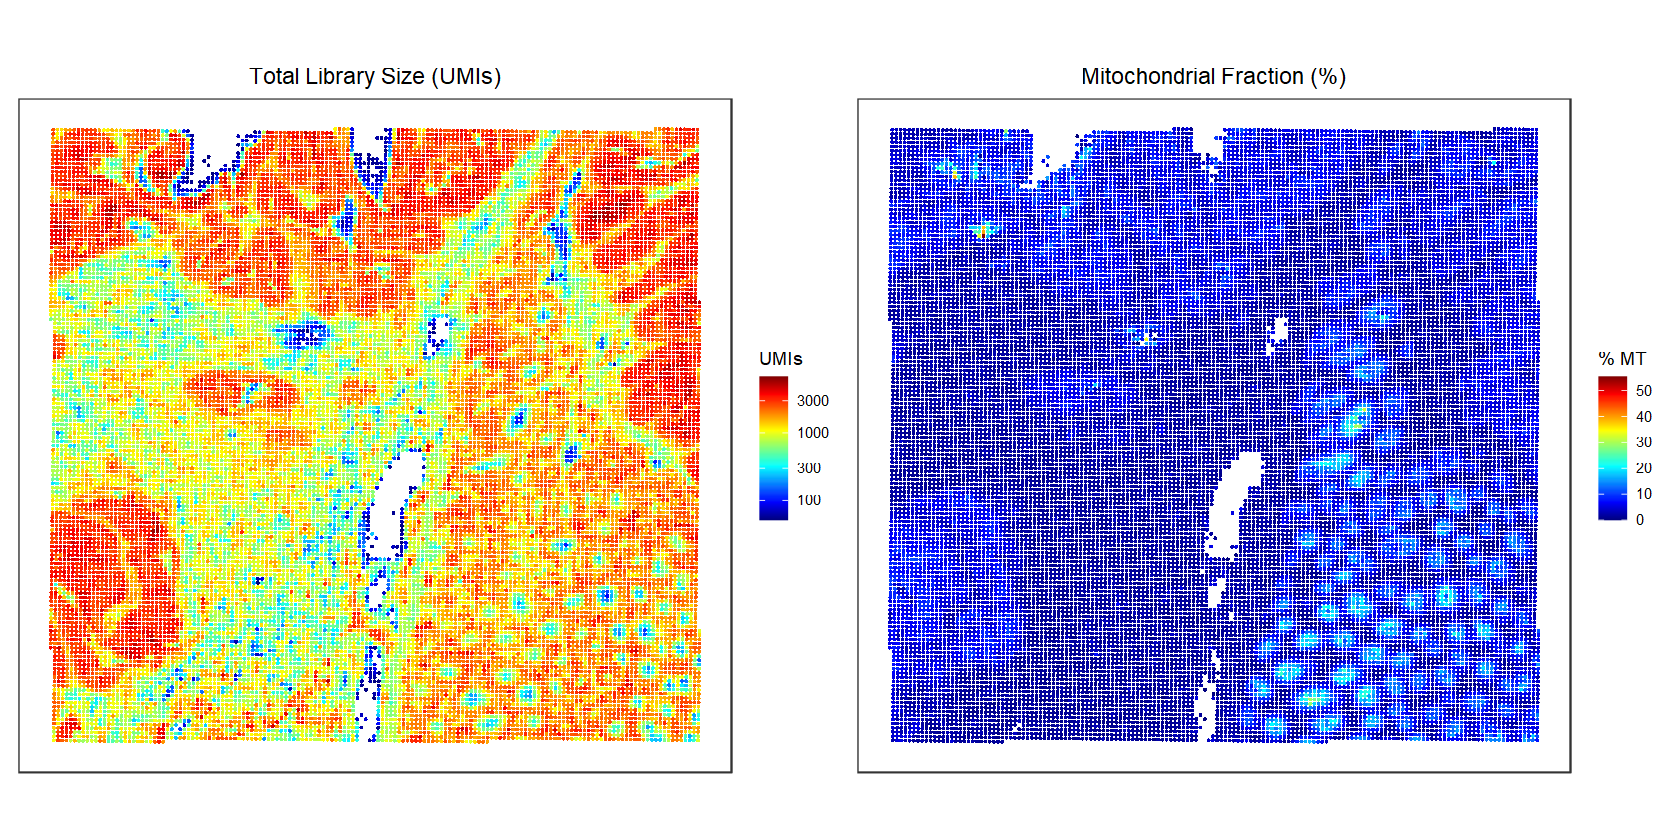

In [11]:
# Map total library size on log10 scale across full slide
p_spatial_lib  <- plotCoords(
  spe, 
  annotate = "sum", 
  point_size = 0.5 
) +
  scale_color_gradientn(
    colors = pals::jet(), 
    trans = "log10", 
    name = "UMIs"
  ) +
  labs(title = "Total Library Size (UMIs)")

# Map mitochondrial fraction across full slide
p_spatial_mito  <- plotCoords(
  spe, 
  annotate = "subsets_Mito_percent", 
  point_size = 0.5
) +
  scale_color_gradientn(
    colors = pals::jet(), 
    name = "% MT"
  ) +
  labs(title = "Mitochondrial Fraction (%)")

p_spatial_lib  + p_spatial_mito

Comparing these spatial maps to the segmented cell plots in Notebook 04 highlights two immediate visual differences.

First, because `plotCoords()` plots raw pixel row coordinates (`pxl_row_in_fullres`) along a standard Cartesian $y$-axis (increasing upward), the spatial maps appear vertically flipped relative to the H&E raster image above. 

Second, notice the absence of white "holes" inside the colonic glands: whereas cell segmentation only draws polygons around stained nuclei and leaves internal acinar lumens blank, the 16-µm grid tiles continuously across the tissue, capturing low-level diffused transcripts (50–200 UMIs, visible in blue) that fill in the glandular cavities.

### Spatial diagnosis of candidate exclusions

We now project our boolean exclusion flags (`qc_lib_size` and `qc_mito_prop`) onto the physical coordinates using `plotCoords()` to evaluate *which* histological structures would be eliminated by these initial candidate cutoffs across our ROI.

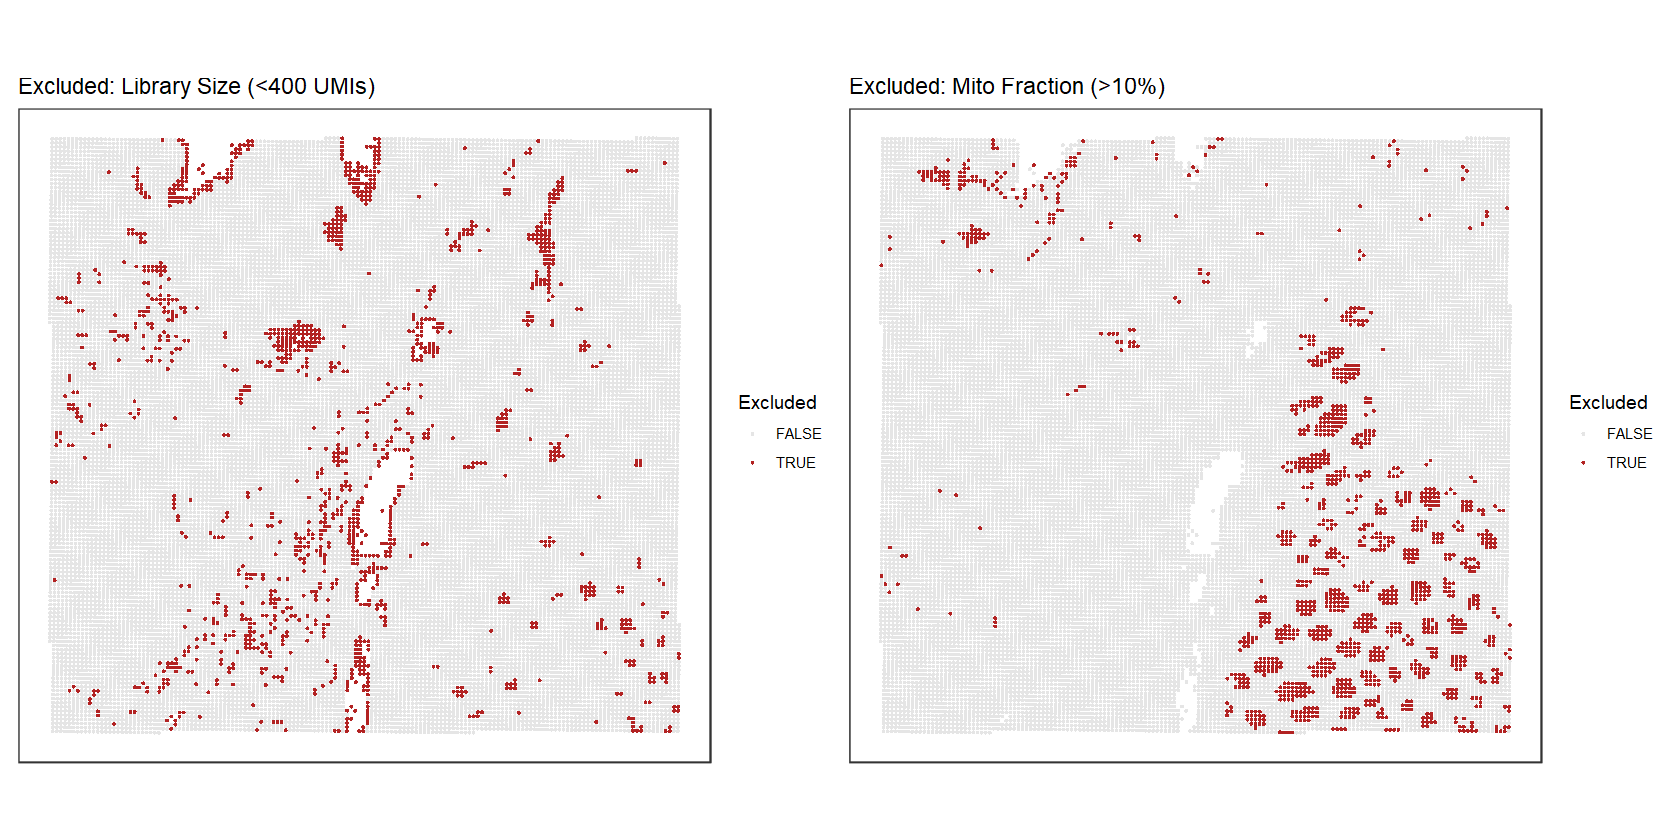

In [12]:
# Full-slide exclusions by Library Size (<400 UMIs)
p_excl_lib <- plotCoords(
  spe, 
  annotate = "qc_lib_size", 
  point_size = 0.5
) +
  scale_color_manual(
    values = c("FALSE" = "gray90", "TRUE" = "firebrick"), 
    name = "Excluded"
  ) +
  labs(title = "Excluded: Library Size (<400 UMIs)")

# Full-slide exclusions by Mitochondrial Fraction (>10%)
p_excl_mito <- plotCoords(
  spe, 
  annotate = "qc_mito_prop", 
  point_size = 0.5
) +
  scale_color_manual(
    values = c("FALSE" = "gray90", "TRUE" = "firebrick"), 
    name = "Excluded"
  ) +
  labs(title = "Excluded: Mito Fraction (>10%)")

# Display the full-slide exclusions side-by-side
p_excl_lib + p_excl_mito

Mapping these initial exclusion flags onto the tissue reveals why naive global cutoffs are problematic for 16-µm binned data. While this filter catches low-density bins along the physical tissue tears and stromal clefts, it also flags a large number of bins inside and around intact colonic glands (where partial overlap with the central crypt lumen or mucin-rich cytoplasm naturally reduces UMI density per 16-µm square).

Because 16-µm squares pool transcripts across multiple metabolically active epithelial cells, a strict 10% ceiling flags entire clusters of healthy colonic glands in the lower-right region of the plot. 

Rather than discarding intact glandular epithelium with overly aggressive global cutoffs, we must pair **relaxed global thresholds** (to catch extreme edge/tear failures) with **local neighborhood outlier detection (`SpotSweeper`)**.

## Local outlier detection with `SpotSweeper`

### Adapting spatial QC to a regular grid

In the previous notebook, we applied `SpotSweeper` to segmented cell polygons. Here, our observations are **16 × 16 µm square bins** (256 µm²). While the mathematical mechanics of `SpotSweeper::localOutliers()` remain identical, the biological interpretation shifts fundamentally:

| Feature | Segmented Cells | Binned Grid (16 µm) |
| :--- | :--- | :--- |
| **Observation unit** | Variable biological cell polygons (`cellSeg`) | Fixed geometric squares on a continuous lattice |
| **Transcriptional content** | Reads from a single isolated cell | A composite mixture of 1–3 cells, partial fragments, or extracellular matrix |
| **Low UMI cause** | Small cell volume, quiescent lineage, or lysed membrane | Partial tissue coverage, empty glandular lumen, or acellular stroma |
| **Spatial neighborhood (k-NN)** | Irregular centroid distances (dense crypts vs. sparse stroma) | Strictly uniform physical spacing across the capture grid |
| **Local outlier meaning** | A compromised cell divergent from its cellular neighbors | A bin with partial tissue adherence, cutting tears, or mixed-boundary artifacts |

### Detecting focal anomalies across the grid

On a regular 16 µm grid, the $k = 36$ nearest-neighbor graph covers a uniform concentric radius of approximately 100 µm around each target bin. We run `localOutliers()` on total counts, feature diversity, and mitochondrial ratio, using the same robust neighborhood threshold (default `cutoff = 3` local MADs).

> Because sequencing counts follow log-normal distributions, setting `log = TRUE` for `sum` and `detected` stabilizes local variance across dynamic ranges. Percentages are already bounded on an arithmetic scale, so we maintain `log = FALSE`. By default, `localOutliers()` evaluates a spatial neighborhood of $k = 36$ nearest physical neighbors.

In [13]:
# Identify local outliers across uniform 16µm spatial neighborhoods (k = 36)
spe <- localOutliers(
  spe, 
  metric = "sum", 
  direction = "lower", 
  log = TRUE, 
)

spe <- localOutliers(
  spe, 
  metric = "detected", 
  direction = "lower", 
  log = TRUE, 
)

spe <- localOutliers(
  spe, 
  metric = "subsets_Mito_percent", 
  direction = "higher", 
  log = FALSE, 
)

Warning message in BiocParallel::MulticoreParam(workers = workers):
"MulticoreParam() not supported on Windows, use SnowParam()"
Warning message in BiocParallel::MulticoreParam(workers = workers):
"MulticoreParam() not supported on Windows, use SnowParam()"
Warning message in BiocParallel::MulticoreParam(workers = workers):
"MulticoreParam() not supported on Windows, use SnowParam()"


A bin is deemed of low quality if it fails **any** of our individual local QC criteria. We therefore combine the three metric-specific flags using a logical OR (`|`) into a single composite boolean column, `spe[["local_outliers"]]`.

In [14]:
# Construct a composite boolean flag (TRUE if flagged by ANY of the three metrics)
spe[["local_outliers"]] <- as.logical(spe[["sum_outliers"]]) |
  as.logical(spe[["detected_outliers"]]) |
  as.logical(spe[["subsets_Mito_percent_outliers"]])

To assess the impact of spatially-aware filtering and determine how each metric contributes to the overall exclusion rate, we tabulate the flagged bin counts and their corresponding percentages across the dataset.

In [15]:
# Summarize individual and composite local outlier counts
data.frame(
  Metric = c(
    "Low Library Size (sum)", 
    "Low Gene Diversity (detected)", 
    "High Mitochondrial (% MT)", 
    "Combined Local Outliers"
  ),
  Flagged_Binss = c(
    sum(spe[["sum_outliers"]], na.rm = TRUE),
    sum(spe[["detected_outliers"]], na.rm = TRUE),
    sum(spe[["subsets_Mito_percent_outliers"]], na.rm = TRUE),
    sum(spe[["local_outliers"]], na.rm = TRUE)
  ),
  Percent_Dataset = round(c(
    mean(spe[["sum_outliers"]], na.rm = TRUE),
    mean(spe[["detected_outliers"]], na.rm = TRUE),
    mean(spe[["subsets_Mito_percent_outliers"]], na.rm = TRUE),
    mean(spe[["local_outliers"]], na.rm = TRUE)
  ) * 100, 2)
)

Metric,Flagged_Binss,Percent_Dataset
<chr>,<int>,<dbl>
Low Library Size (sum),83,0.38
Low Gene Diversity (detected),136,0.62
High Mitochondrial (% MT),61,0.28
Combined Local Outliers,204,0.93


Across the entire section, `SpotSweeper` flags only **204 bins (0.93%)** as combined local outliers. The majority of these localized anomalies stem from aberrant mitochondrial spikes (206 cells, 0.59%), whereas transcriptomic dropouts are exceedingly rare (58 cells for library size and 72 cells for gene diversity). 

While rigid global cutoffs threatened to eliminate nearly 14% of the dataset, spatially-aware filtering demonstrates that most low-count cells are viable histological components sharing similar transcript levels with their physical neighbors.

### Spatial distribution of binned local outliers

To verify where these **204 flagged bins** reside anatomically, we map the composite `local_outliers` flag across our ROI coordinates using `plotCoords()`.

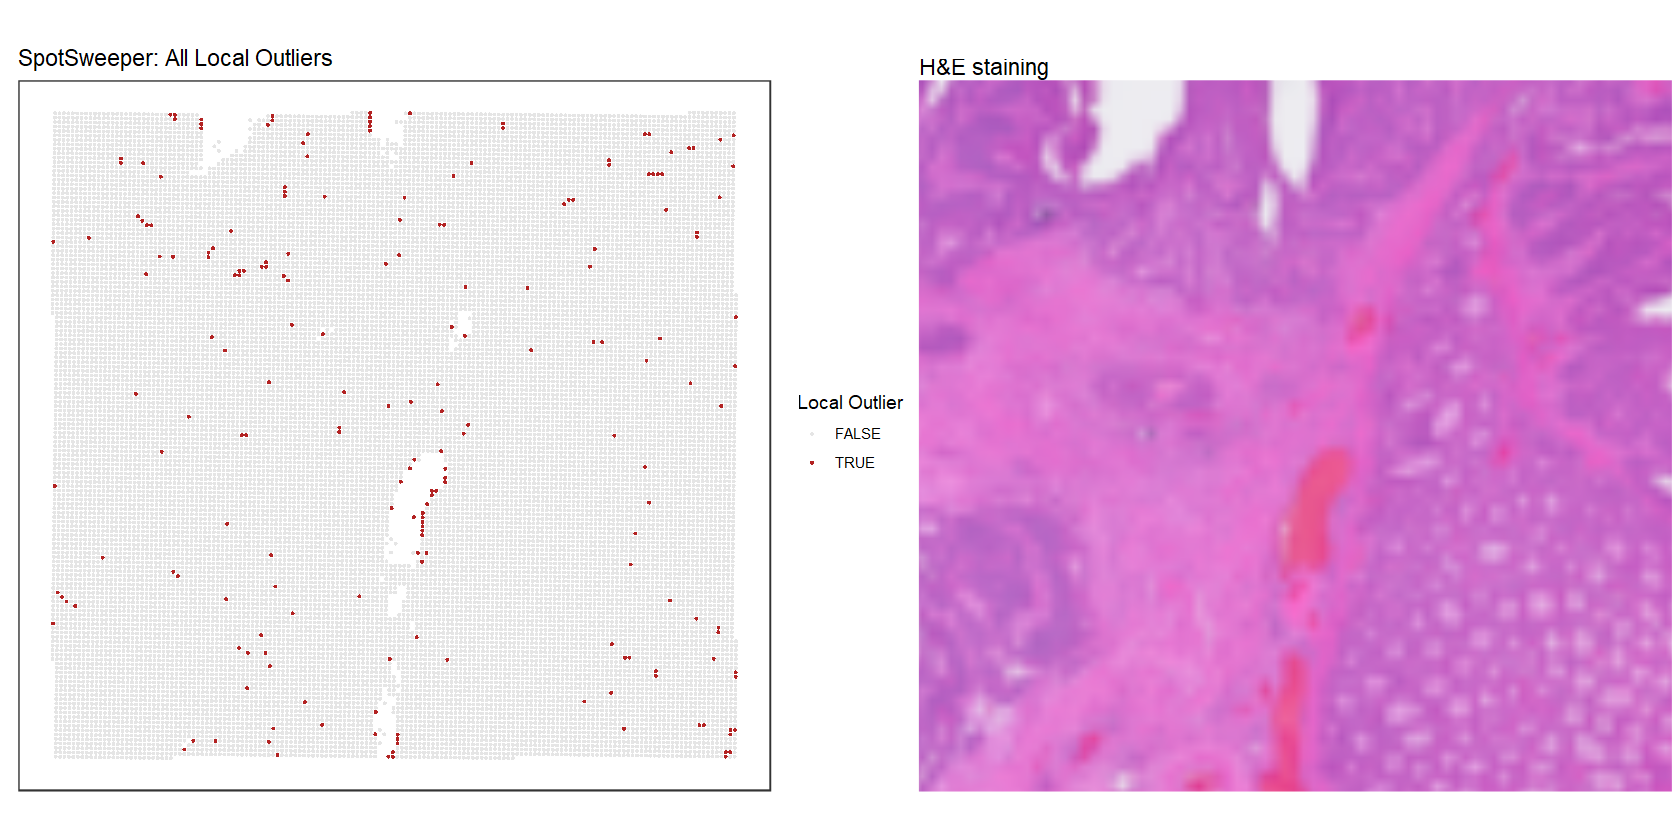

In [16]:
# Macroscopic slide view of all local outliers
p_local_macro <- plotCoords(
  spe, 
  annotate = "local_outliers", 
  point_size = 0.5
) +
  scale_color_manual(
    values = c("FALSE" = "gray90", "TRUE" = "firebrick"), 
    name = "Local Outlier"
  ) +
  labs(title = "SpotSweeper: All Local Outliers ")

# H&E stain view

p_tissue <- plotVisium(spe, spots = FALSE, zoom = TRUE) +
  labs(title = "H&E staining")

# Display
p_local_macro + p_tissue

Rather than eliminating entire glandular clusters or low-density stromal compartments, `SpotSweeper`'s local outliers manifest as isolated, focal events scattered across the grid. In the colonic gland and stromal regions where our initial global cutoffs indiscriminately flagged whole anatomical structures, `SpotSweeper` recognizes that these 16-µm bins are consistent with their immediate spatial neighbors ($k = 36$), successfully preserving intact tissue morphology. The flagged bins correspond to genuine focal technical dropouts, abrupt luminal transitions, or localized cellular damage bordering the physical tissue tears and smears whose metrics deviate sharply from their surrounding microenvironment.

### Evaluating local Z-scores

Comparing the distribution of local mitochondrial Z-scores (`subsets_Mito_percent_z`) against our initial global cutoff (`qc_mito_prop > 10%`) illustrates how spatial context recalibrates outlier detection on a regular 16-µm grid.

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


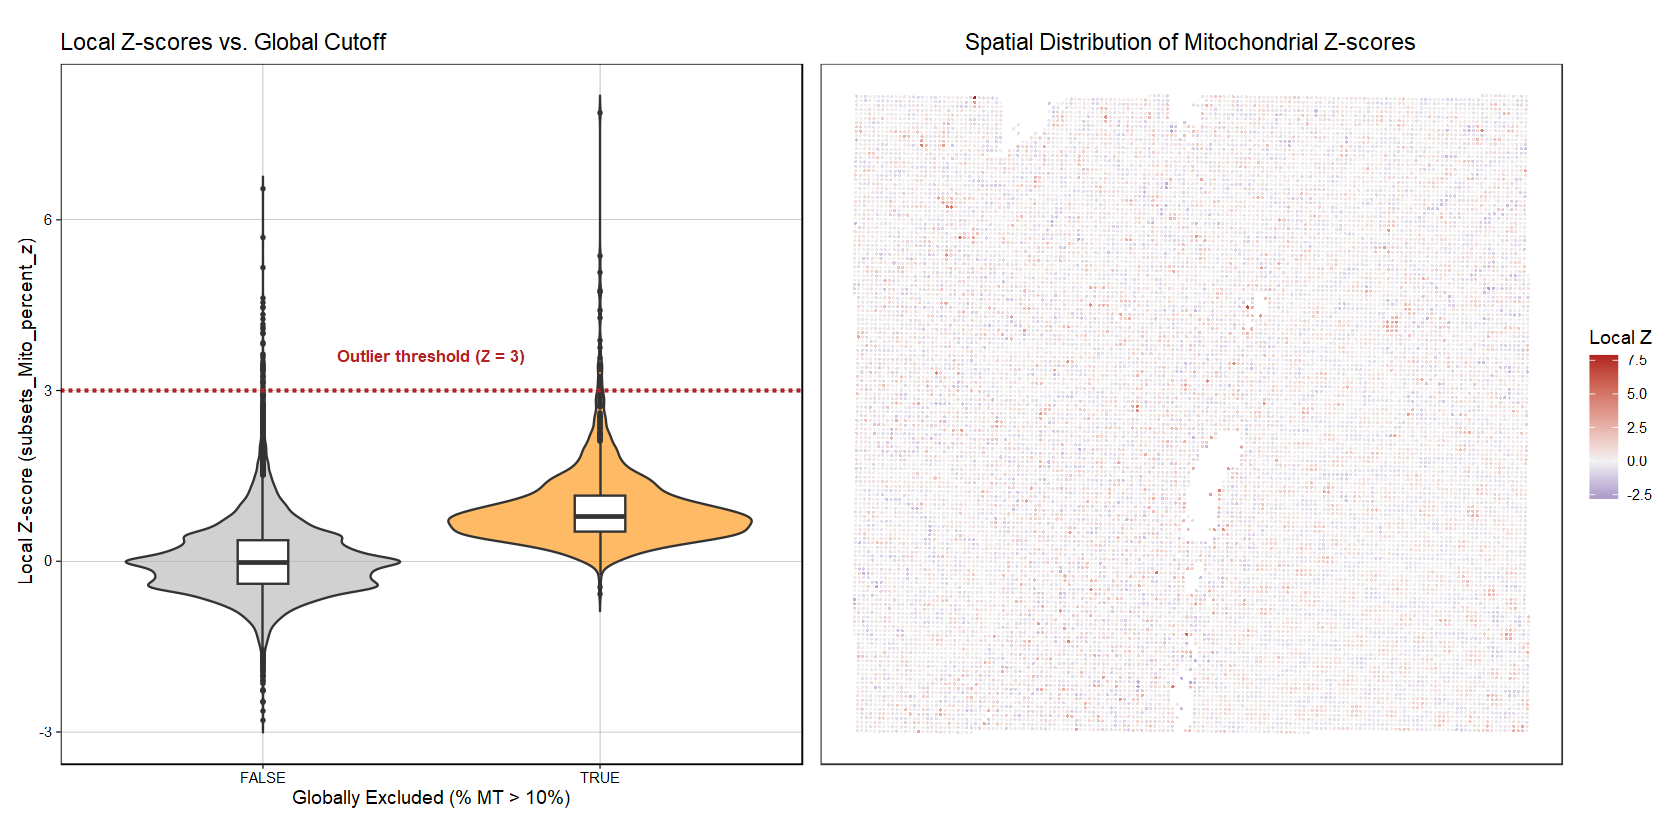

In [17]:
options(repr.plot.width = 14, repr.plot.height = 7)

# Statistical distribution: Local Z-score by global status
p_violin <- ggplot(
  as.data.frame(colData(spe)), 
  aes(x = qc_mito_prop, y = subsets_Mito_percent_z, fill = qc_mito_prop)
) +
  geom_violin(trim = FALSE, alpha = 0.6, show.legend = FALSE) +
  geom_boxplot(
    width = 0.15, fill = "white", outlier.size = 0.5, show.legend = FALSE) +
  geom_hline(
    yintercept = 3, linetype = "dashed", color = "firebrick", linewidth = 0.9) +
  annotate(
    "text", x = 1.5, y = 3.6, label = "Outlier threshold (Z = 3)", 
    color = "firebrick", fontface = "bold", size = 3.5) +
  scale_fill_manual(values = c("FALSE" = "gray70", "TRUE" = "darkorange")) +
  theme_linedraw(base_size = 11) +
  theme(panel.grid.minor = element_blank()) +
  labs(
    title = "Local Z-scores vs. Global Cutoff",
    x = "Globally Excluded (% MT > 10%)",
    y = "Local Z-score (subsets_Mito_percent_z)"
  )

# Spatial distribution of continuous local Z-scores
p_z_spatial <- plotCoords(
  spe, annotate = "subsets_Mito_percent_z"
) +
  scale_color_gradient2(
    low = "navy", mid = "gray95", high = "firebrick", midpoint = 0, name = "Local Z") +
  labs(title = "Spatial Distribution of Mitochondrial Z-scores")

# Display side-by-side
p_violin + p_z_spatial

Just as in the segmented dataset, the vast majority of 16-µm bins with >10% mitochondrial content (orange violin)(which corresponded to healthy, metabolically active colonic glands) exhibit local Z-scores well below the outlier threshold (Z ≤ 3), sparing intact glandular epithelium from false-positive removal (left panel). Conversely, `SpotSweeper` still captures genuine localized anomalies (Z > 3) whose absolute mitochondrial percentage sits below 10%, but which spike sharply relative to their quiescent immediate neighbors.

More strikingly, the spatial map of `subsets_Mito_percent_z` is **much more homogeneous** here than in the segmented cell dataset (right panel). In the segmented dataset (Notebook 04), colonic crypts formed thin epithelial rings around empty, unsegmented luminal holes, forcing the k-NN search ($k = 36$) to reach outward into the low-mitochondrial lamina propria and artificially inflating Z-scores along crypt borders. On our 16-µm binned grid, squares tile continuously across the glands (and each 256 µm² bin already averages transcripts across multiple adjacent cells).

Because the k-NN neighborhood sits on a uniform lattice without empty internal voids, local medians transition smoothly across gland boundaries and eliminate the pink ring artifacts! Consequently, extreme local Z-scores (Z > 3) are cleanly restricted to genuine focal cellular damage and compromised bins bordering the physical tissue tears and smears.

## Two-tiered quality control

### Combining global floors with local context

Just as in our segmented workflow, neither filtering regime is sufficient on its own for a 16-µm grid:

- **Local filtering alone (`k = 36`)** misses contiguous technical defects (such as wide tears or necrotic patches) where neighboring bins share uniformly degraded metrics.
- **Strict global cutoffs (`sum < 400`, `detected < 200`, `mito > 10%`)** over-penalize intact biology, flagging 1,428 low-count stromal bins and 1,358 metabolically active colonic crypt bins.

We therefore apply the same **two-tiered quality control strategy**, calibrated to the empirical contours of our 16-µm binned distributions:

1. **Relaxed global floor (`sum < 125`, `detected < 125`, `mito > 18%`):** Acts as an absolute technical safety net to prune severely depleted or damaged bins along wide tears and margins, regardless of their neighbors.
2. **Local neighborhood outliers (`local_outliers`):** Captures focal dropouts and partial-coverage edge anomalies embedded within otherwise intact tissue compartments.

In [18]:
# Relaxed global floor thresholds (to be applied)
min_sum      <- 125   # Minimum total UMIs per bin
min_detected <- 125   # Minimum unique genes per bin
max_mito     <- 18    # Maximum mitochondrial percentage per bin

### Visually grounding the relaxed global floor

To verify that our relaxed binned thresholds align with the empirical distributions, we re-plot the bivariate scatter plots and 2D density contours (`ggside`), comparing our new relaxed global floors (solid/dashed lines) against the initial candidate thresholds (dotted lines).

In [19]:
# Plot 1: Library size vs. detected genes with marginal histograms
p_scatter1 <- ggcells(spe, aes(x = detected, y = sum)) +
  geom_point(alpha = 0.75, size = 1) +
  geom_density_2d(color = "blue") +
  scale_x_log10() +
  scale_y_log10() +
  geom_xsidehistogram(bins = 50, fill = "gray70", color = "white") +
  geom_ysidehistogram(bins = 50, fill = "gray70", color = "white") +
  # Relaxed global floor
  geom_vline(xintercept = min_detected, color = "red", linetype = "dashed") +
  geom_hline(yintercept = min_sum, color = "red", linetype = "dashed") +
  labs(
    x = "Detected Genes (log10)",
    y = "Total UMIs (log10)",
    title = "Library Size vs. Detected Genes"
  ) +
  theme_classic() +
  ggside::theme_ggside_void()

# Plot 2: Mitochondrial proportion vs. detected genes with marginal histograms
p_scatter2 <- ggcells(spe, aes(x = detected, y = subsets_Mito_percent)) +
  geom_point(alpha = 0.5, size = 1) +
  geom_density_2d(color = "blue") +
  scale_x_log10() +
  geom_xsidehistogram(bins = 50, fill = "gray70", color = "white") +
  geom_ysidehistogram(bins = 50, fill = "gray70", color = "white") +
  # Relaxed global floor
  geom_vline(xintercept = min_detected, color = "red", linetype = "dashed") +
  geom_hline(yintercept = max_mito, color = "red", linetype = "dashed") +
  labs(
    x = "Detected Genes (log10)",
    y = "Mitochondrial Fraction (%)",
    title = "Mitochondrial Fraction vs. Detected Genes"
  ) +
  theme_classic() +
  ggside::theme_ggside_void()

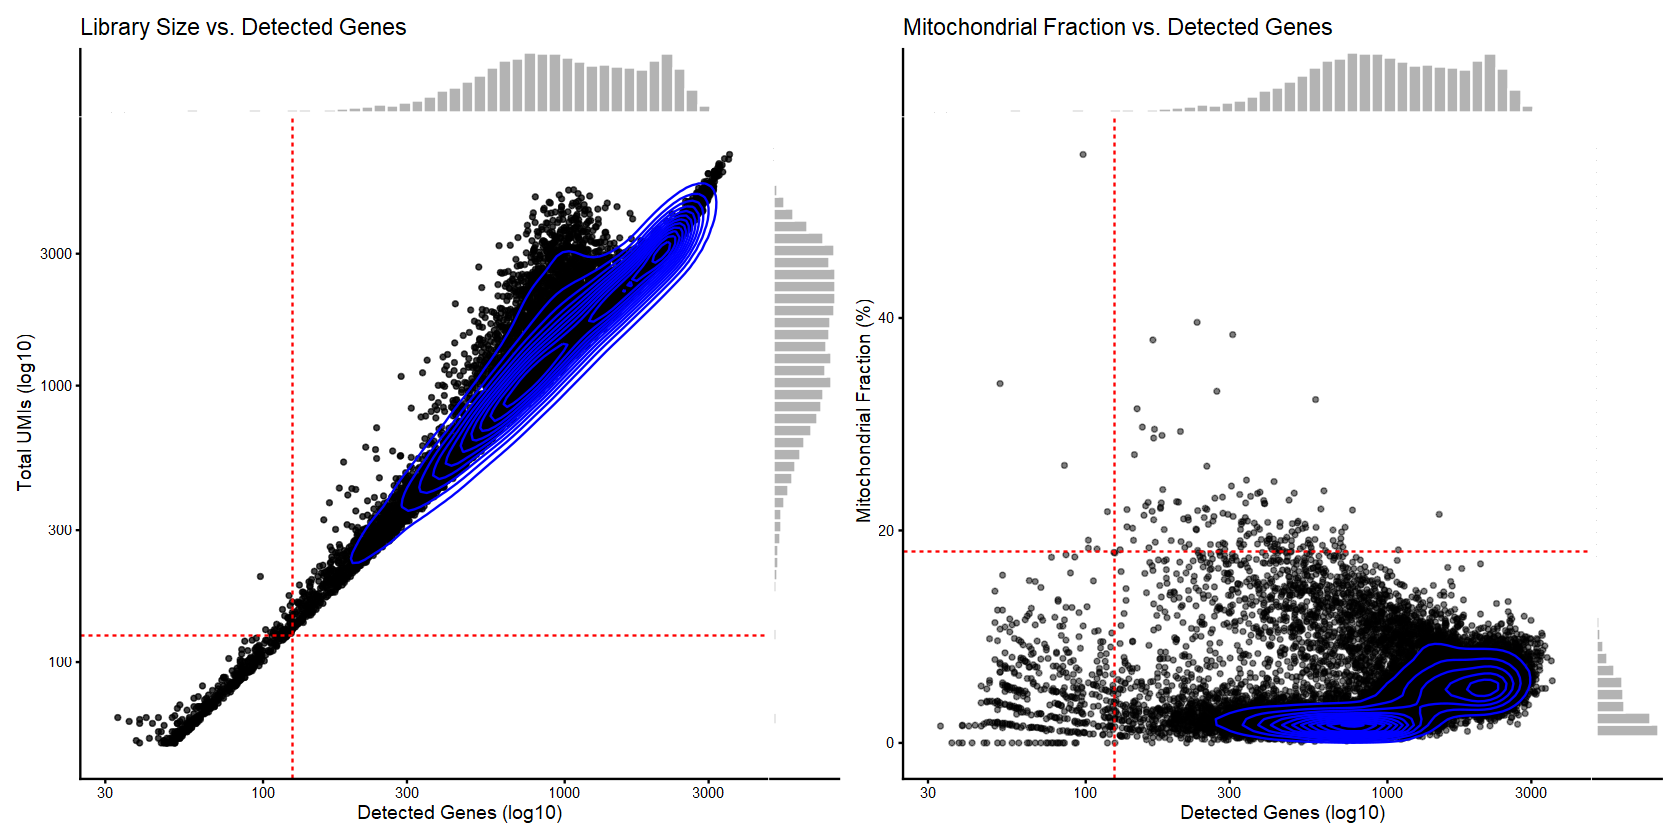

In [20]:
# Display side-by-side
p_scatter1 + p_scatter2

In the left panel (`sum` vs. `detected`), our relaxed floor (`sum < 125`, `detected < 125`) sits just below the outermost 2D density contour of the main tissue population. Rather than slicing into viable low-density stromal bins or partially luminal gland squares (as the initial 400 UMI / 200 gene cutoffs did), this relaxed boundary cleanly isolates the sparse lower-left tail of depleted bins (those sitting just above our 50-UMI pre-filter from Notebook 01).

In the right panel (`detected` vs. `subsets_Mito_percent`), because 16-µm squares pool transcripts across multiple overlapping cells, the mitochondrial distribution is shifted compared to segmented single cells. Adjusting the mitochondrial cap to 18% aligns with the upper shoulder of the marginal histogram, safely preserving metabolically active colonic glands while still catching severely compromised bins.

In [21]:
# Define relaxed global baseline thresholds (technical floor)
spe[["qc_lib_size"]]  <- spe[["sum"]] < min_sum
spe[["qc_detected"]]  <- spe[["detected"]] < min_detected
spe[["qc_mito_prop"]] <- spe[["subsets_Mito_percent"]] > max_mito

# Combine global flags
spe[["global_outliers"]] <- spe[["qc_lib_size"]] | spe[["qc_detected"]] | spe[["qc_mito_prop"]]

# Combine global and local outliers into our final discard flag
spe[["discard"]] <- spe[["global_outliers"]] | spe[["local_outliers"]]

In [22]:
# Cross-tabulate global vs. local outlier flags
table(Global = spe[["global_outliers"]], Local = spe[["local_outliers"]])

       Local
Global  FALSE  TRUE
  FALSE 21278   134
  TRUE    484    70

In [23]:
# Tabulate final combined discard numbers
table(Discard = spe[["discard"]])

Discard
FALSE  TRUE 
21278   688 

By calibrating our relaxed global thresholds to the 16-µm binned contours, global exclusions drop to **554 bins (2.52%)**. Combined with `SpotSweeper` local outliers (**204 bins, 0.93%**, with **70 bins** overlapping between both tiers and **134 bins** flagged uniquely by the local filter), our final composite `discard` filter removes **688 bins (3.13%)** while preserving **21,278 high-quality bins (96.87%)** out of our initial 21,966 ROI bins.

### Spatial verification of the two-tiered filtering gate

In [24]:
# Panel 1: Relaxed global floor outliers
p_global <- plotCoords(spe, annotate = "global_outliers") +
  scale_color_manual(values = c("FALSE" = "gray90", "TRUE" = "darkorange2"), name = "Global Floor") +
  labs(title = "Relaxed Global Outliers")

# Panel 2: SpotSweeper local outliers
p_local <- plotCoords(spe, annotate = "local_outliers") +
  scale_color_manual(values = c("FALSE" = "gray90", "TRUE" = "firebrick"), name = "Local Outlier") +
  labs(title = "SpotSweeper Local Outliers")

# Panel 3: Final combined discard flag
p_discard <- plotCoords(spe, annotate = "discard") +
  scale_color_manual(values = c("FALSE" = "gray90", "TRUE" = "purple4"), name = "Discard Flag") +
  labs(title = "Final Combined Discard")

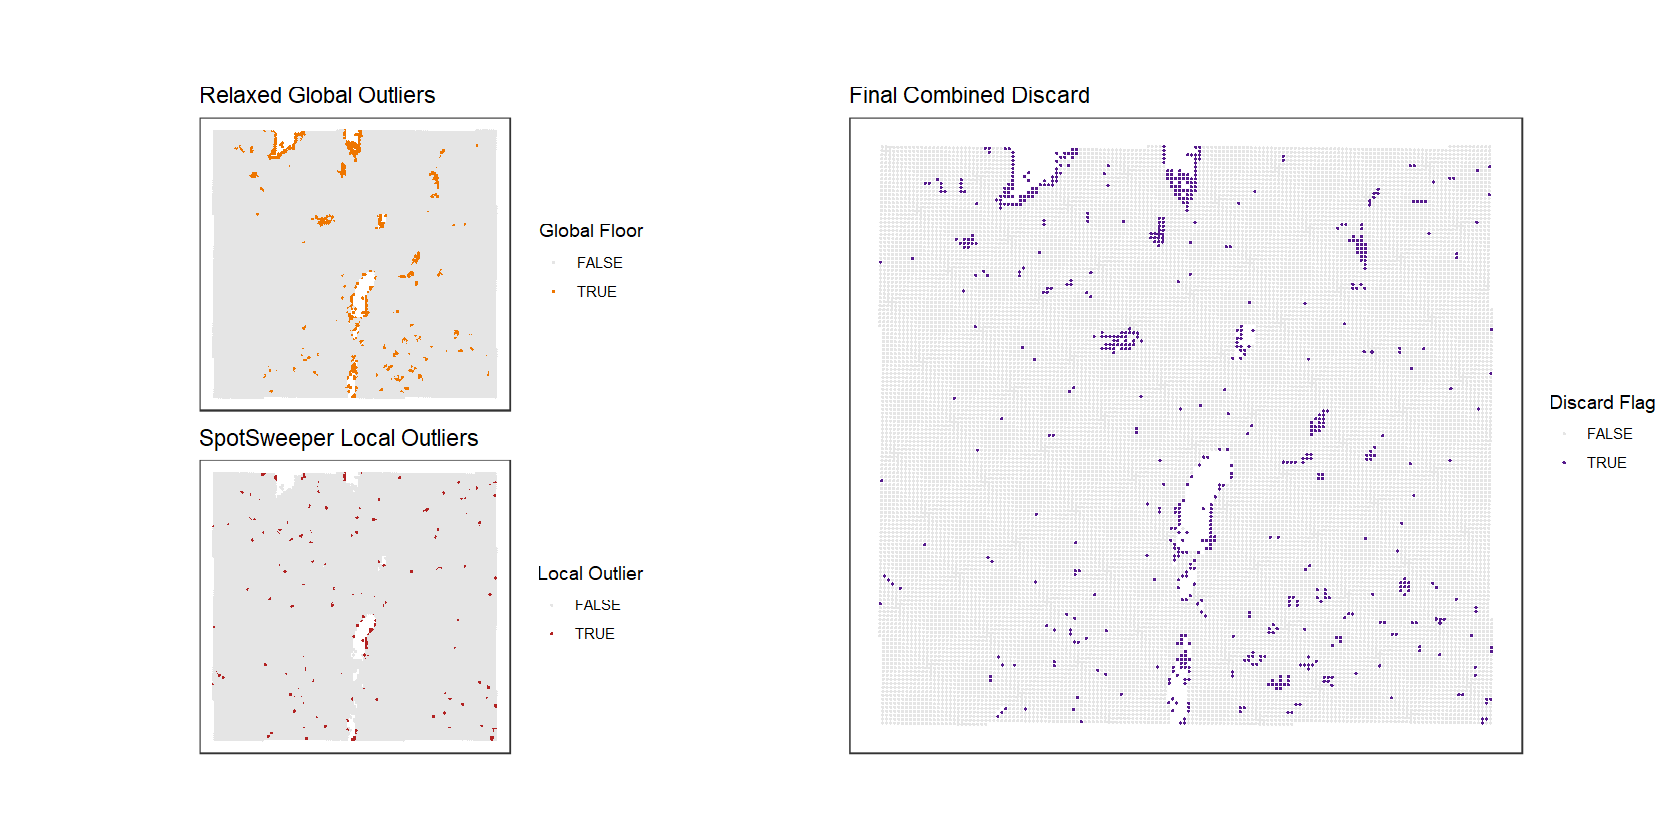

In [25]:
# Display 3-panel spatial synthesis
(p_global / p_local) | p_discard

Crucially, inspecting the spatial map of these final flags confirms the value of our two-tiered approach on binned grids: whereas the initial global thresholds carved out intact colonic glands, the **final relaxed global thresholds** selectively remove low-quality bins lining physical tissue tears and smears, while **`SpotSweeper` local outliers** pinpoint isolated focal anomalies across the parenchyma.

Remarkably, despite the vertical orientation flip between plotting systems (standard Cartesian pixel coordinates in `plotCoords` versus image-registered micron geometries in `plotSpatialFeature`), the composite discard pattern shows striking morphological concordance with our segmented single-cell results from the [previous notebook](./04-quality_control_VisiumHD_segmented.ipynb):

- Intact colonic crypts are completely spared in both representations, avoiding the biological erosion caused by rigid global cuts.
- Exclusions consistently map to the exact same anatomical structures, most notably the debris lining the central vascular/luminal fissure, perimeter margin artifacts, and scattered focal dropouts across the stroma.

## Object subsetting & final cleanup

### Filtering low-quality bins and unexpressed genes

Following the sequential pruning logic established in the previous notebook, we filter across both dimensions of `spe`:

1. **Bin filtering (`!spe$discard`):** Subsets columns to retain the 21,278 bins passing our two-tiered QC criteria.
2. **Gene filtering (`rowSums(counts(spe)) > 0`):** Prunes inactive rows that have zero detected counts following ROI cropping and bin exclusion, preventing divide-by-zero (`NaN`) errors in downstream normalization and dimensionality reduction.

In [26]:
# Step 1: Filter low-quality / outlier bins
spe <- spe[, !spe[["discard"]]]

# Step 2: Prune unexpressed genes across the remaining bins
spe <- spe[rowSums(counts(spe)) > 0, ]

# Inspect the final dimensions of the filtered object
spe

class: SpatialExperiment 
dim: 18027 21278 
metadata(2): resouces spatialList
assays(1): counts
rownames(18027): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(4): ID Symbol Type subsets_Mito
colnames(21278): s_016um_00144_00175-1 s_016um_00204_00145-1 ...
  s_016um_00231_00291-1 s_016um_00193_00227-1
colData names(32): barcode in_tissue ... global_outliers discard
reducedDimNames(0):
mainExpName: Gene Expression
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

After executing both filtering steps, our clean 16-µm binned `SpatialExperiment` object retains **21278 high-quality bins** (removing 688 compromised bins) and **18027 active genes** (pruning 58 unexpressed genes from the initial 18,085-gene probe set).

### Saving the quality-controlled dataset

We serialize our filtered, two-tiered quality-controlled `SpatialExperiment` object to disk using `HDF5Array::saveHDF5SummarizedExperiment()`, establishing a reproducible checkpoint for downstream normalization and dimensionality reduction.

In [27]:
# Define the standardized output directory for the QC-filtered binned object
qc_out_dir <- "output/spe_visiumhd_binned_qc"

# Serialize the filtered SpatialExperiment object and its HDF5 DelayedMatrix to disk
saveHDF5SummarizedExperiment(
  x = spe,
  dir = qc_out_dir,
  replace = TRUE
)

# Verify directory creation and exported HDF5 payload
list.files(qc_out_dir, full.names = TRUE)

[1] "output/spe_visiumhd_binned_qc/assays.h5"
[2] "output/spe_visiumhd_binned_qc/se.rds"

### Clearing the workspace

Even though our `SpatialExperiment` count matrix uses an out-of-memory `DelayedMatrix` (HDF5) backend, spatial coordinate tables, histological image rasters, `SpotSweeper` neighborhood graphs, and `ggplot2` visualization layers still occupy substantial active RAM. We clear the active workspace and trigger garbage collection (`gc()`) to return allocated memory to the system and close open HDF5 file handles.

*(Note: In interactive IDEs such as RStudio, VS Code, or Positron, restarting the active R session is also recommended before opening the next notebook).*

In [28]:
# Remove all objects from the global environment and free up system RAM
rm(list = ls())
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,9989096,533.5,17128098,914.8,17128098,914.8
Vcells,20499623,156.4,59706807,455.6,59326661,452.7
